# Lab 8: Two Ways to Generate

The question I'm working on: on the same small digits, how do a GAN and a diffusion model compare, and why does one kind of GAN fall apart where the other doesn't? I write the GAN losses, WGAN-GP and a DDPM diffusion model from scratch, check each one against something I can work out exactly, and then score them next to the starter's VAE. The starter supplies the data, the networks, the noise schedule, the VAE and the scoring, unchanged. Every trained model gets seeds 0, 1 and 2.

In [1]:
import json
import math
import os
import platform
import subprocess
import sys
import time

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import lab08_starter as S

SEEDS = [0, 1, 2]
SAMPLE_SEED = 9            # noise seed for every evaluation draw (matches S.VAE.sample's default)
N_SAMPLES = 359            # every Frechet distance, precision and recall uses 359 images
DEVICE = "cpu"
BATCH_SIZE = 128
GAN_STEPS = 4000           # generator steps
GAN_BETAS = (0.5, 0.999)
STANDARD_LR_G, STANDARD_LR_D = 5e-4, 2e-4
WGAN_LR, WGAN_CRITIC_STEPS, GP_WEIGHT = 5e-4, 3, 10.0
DIFFUSION_STEPS = 4000
RING_HIDDEN, RING_LR = 128, 2e-3
DIGIT_HIDDEN, DIGIT_LR = 256, 1e-3
T_STEPS = 100
DETERMINISTIC_KS = [5, 10, 25, 50, 100]
os.makedirs("figures", exist_ok=True)
results = {}
run_start = time.perf_counter()

print("python", platform.python_version(), "| torch", torch.__version__, "| threads", torch.get_num_threads(),
      "| venv kernel:", sys.prefix.endswith(".venv"))

python 3.12.13 | torch 2.2.2 | threads 8 | venv kernel: True


The imports and settings are in place. Every run below uses seeds 0, 1 and 2, and every evaluation draw uses sample seed 9, so any two runs I compare start from the same noise.

## Run the starter once

Before I change anything I want to know the environment works, so I run the starter unmodified.

In [2]:
starter_start = time.perf_counter()
starter_run = subprocess.run([sys.executable, "lab08_starter.py"], capture_output=True, text=True, check=True)
print(starter_run.stdout)
print(f"starter took {time.perf_counter() - starter_start:.1f}s")

train (1438, 64) test (359, 64)
modes covered by real ring data: 8
alpha_bar at the last step: 0.005618760362267494
baseline VAE (30 epochs): {'frechet': 31.143, 'precision': 0.847, 'recall': 0.201, 'nearest_train': 1.269}
saved starter_check.png

starter took 5.6s


The starter runs as given. Its 30-epoch VAE scores Fréchet 31.1, precision 0.85 and recall 0.20, which already tells me something: on this feature network a weak generator can look precise and still cover very little of the data.

## One ruler for every score

Comparing generators only means something if they're all measured the same way. So I train the starter's feature network once (seed 0) and use it for every Fréchet distance, precision and recall in this notebook, always 359 generated images against the 359 test images. On top of the starter's scores I add:

- **Nearest train:** how close each sample is to a training image, to catch copying.
- **Digit counts:** which digit the classifier thinks each sample is, to catch dropped modes.
- **Digit TV:** how far the digit mix is from the test mix.

The scorer refuses anything outside [0, 1], so a diffusion sample can't be scored before it's rescaled.

In [3]:
Xtr, ytr, Xte, yte = S.load_task()
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))
print(f"pixel range: {Xtr.min().item():.2f} to {Xtr.max().item():.2f}")
print("train images per digit:", torch.bincount(ytr, minlength=10).tolist())
print("test images per digit: ", torch.bincount(yte, minlength=10).tolist())

feature_net = S.train_feature_net(Xtr, ytr)       # seed 0 inside; trained ONCE, reused for every score
test_features = S.get_features(feature_net, Xte)
with torch.no_grad():
    feature_net_accuracy = (feature_net(Xte).argmax(1) == yte).float().mean().item()
test_shares = torch.bincount(yte, minlength=10).double() / len(yte)
print(f"feature network test accuracy: {feature_net_accuracy:.3f}")


def score_images(images, expected_count=N_SAMPLES):
    """Score images that are ALREADY in [0, 1] (diffusion samples must go through to_unit_range first).
    Returns the starter's four scores plus nearest_train_min, digit_counts, digits_present, tv."""
    assert len(images) == expected_count, f"expected {expected_count} images, got {len(images)}"
    assert images.min() >= 0 and images.max() <= 1, "images must be in [0, 1] before scoring"
    images = images.detach()
    scores = S.score_samples(images, test_features, feature_net, Xtr)
    distances = S.nearest_train_distance(images, Xtr)
    with torch.no_grad():
        predicted = feature_net(images).argmax(1)
    counts = torch.bincount(predicted, minlength=10)
    shares = counts.double() / len(images)
    scores.update({"nearest_train_min": float(distances.min()),
                   "digit_counts": [int(c) for c in counts],
                   "digits_present": int((counts > 0).sum()),
                   "tv": float(0.5 * (shares - test_shares).abs().sum())})
    return scores


# Reference block: what the scores look like for real images
test_to_train = S.nearest_train_distance(Xte, Xtr)
subset_generator = torch.Generator().manual_seed(0)
train_subset = Xtr[torch.randperm(len(Xtr), generator=subset_generator)[:N_SAMPLES]]
results["feature_net_accuracy"] = feature_net_accuracy
results["reference"] = {
    "test_nearest_train_mean": float(test_to_train.mean()),
    "test_nearest_train_min": float(test_to_train.min()),
    "test_digit_counts": [int(c) for c in torch.bincount(yte, minlength=10)],
    "train_subset_score": score_images(train_subset),   # nearest-train is 0 here: these images are training images
}
print("reference: real test images to nearest training image, mean "
      f"{results['reference']['test_nearest_train_mean']:.3f}, min {results['reference']['test_nearest_train_min']:.3f}")
print("reference: 359 real training images scored as if generated:",
      {k: (round(v, 3) if isinstance(v, float) else v) for k, v in results["reference"]["train_subset_score"].items()})

train (1438, 64) test (359, 64)
pixel range: 0.00 to 1.00
train images per digit: [151, 147, 141, 154, 151, 142, 137, 140, 136, 139]
test images per digit:  [27, 35, 36, 29, 30, 40, 44, 39, 38, 41]


feature network test accuracy: 0.972
reference: real test images to nearest training image, mean 1.068, min 0.538
reference: 359 real training images scored as if generated: {'frechet': 2.833, 'precision': 0.9, 'recall': 0.911, 'nearest_train': 0.0, 'nearest_train_min': 0.0, 'digit_counts': [43, 39, 27, 38, 35, 34, 39, 45, 33, 26], 'digits_present': 10, 'tv': 0.111}


The feature network gets 0.972 on the test digits. To know what a perfect generator would score, I scored 359 real training images as if they were generated:

- **Fréchet 2.83, precision 0.90, recall 0.91:** so even perfect samples don't reach recall 1 with 359 images.
- **Nearest train:** real test images sit 1.07 from their nearest training image on average and 0.54 at the closest. That's what a genuinely new digit looks like; a copy would be near 0.

## Piece 1: GAN losses from the logit

The discriminator gives a logit `s`, and D = sigmoid(s). Taking the log of a sigmoid that has saturated at 0 or 1 gives -inf, so I write every loss with softplus instead:

- **Discriminator:** -mean log D(real) - mean log(1 - D(fake)).
- **Original generator loss:** mean log(1 - D(G(z))), minimised.
- **Non-saturating generator loss:** -mean log D(G(z)).

I don't trust them until they pass three checks.

In [4]:
def _reduce(values, reduction):
    assert reduction in ("mean", "sum")
    return values.mean() if reduction == "mean" else values.sum()


def discriminator_loss(real_logits, fake_logits, reduction="mean"):
    """-log D(real) - log(1 - D(fake)) with D = sigmoid(logit). Uses log sigmoid(s) = -softplus(-s) and log(1 - sigmoid(s)) = -softplus(s)."""
    return _reduce(F.softplus(-real_logits), reduction) + _reduce(F.softplus(fake_logits), reduction)


def generator_loss_original(fake_logits, reduction="mean"):
    """The original generator loss, log(1 - D(G(z))). The generator minimizes this one."""
    return _reduce(-F.softplus(fake_logits), reduction)


def generator_loss_nonsaturating(fake_logits, reduction="mean"):
    """The non-saturating generator loss, -log D(G(z))."""
    return _reduce(F.softplus(-fake_logits), reduction)

### Check 1: each loss against its definition

I compare each loss with the textbook formula on 1,000 random logits in float64, scaled up so many are far from zero. Then I try logits of -40, 0 and 40 in float32, where the naive formula should break.

In [5]:
torch.manual_seed(0)
logits_real = torch.randn(1000, dtype=torch.float64) * 4
logits_fake = torch.randn(1000, dtype=torch.float64) * 4
naive_d = -(torch.log(torch.sigmoid(logits_real)).mean() + torch.log(1 - torch.sigmoid(logits_fake)).mean())
naive_gmm = torch.log(1 - torch.sigmoid(logits_fake)).mean()
naive_gns = -torch.log(torch.sigmoid(logits_fake)).mean()
loss_rows = [("discriminator loss", discriminator_loss(logits_real, logits_fake), naive_d),
             ("generator loss, original", generator_loss_original(logits_fake), naive_gmm),
             ("generator loss, non-saturating", generator_loss_nonsaturating(logits_fake), naive_gns)]
check_losses = {"rows": {}}
print(f"{'loss':32s} {'mine':>20s} {'definition':>20s} {'abs diff':>10s}")
for name, mine, definition in loss_rows:
    diff = float((mine - definition).abs())
    check_losses["rows"][name] = {"mine": float(mine), "definition": float(definition), "abs_diff": diff}
    print(f"{name:32s} {float(mine):20.12f} {float(definition):20.12f} {diff:10.2e}")
check_losses["max_abs_diff"] = max(row["abs_diff"] for row in check_losses["rows"].values())
check_losses["pass"] = check_losses["max_abs_diff"] < 1e-10
print("max abs diff", f"{check_losses['max_abs_diff']:.2e}", "| pass (< 1e-10):", check_losses["pass"])

stability_logits = torch.tensor([-40.0, 0.0, 40.0])
naive_stability = torch.log(1 - torch.sigmoid(stability_logits))
mine_stability = -F.softplus(stability_logits)
check_losses["stability_float32"] = {"logits": stability_logits.tolist(), "naive_log_one_minus_sigmoid": naive_stability.tolist(),
                                     "mine": mine_stability.tolist()}
print("float32 stability, logits", stability_logits.tolist())
print("  naive log(1 - sigmoid(s)):", naive_stability.tolist())
print("  mine  -softplus(s):       ", mine_stability.tolist())
results["check_losses"] = check_losses

loss                                             mine           definition   abs diff
discriminator loss                     3.369809185009       3.369809185009   2.80e-14
generator loss, original              -1.644090479101      -1.644090479101   2.80e-14
generator loss, non-saturating         1.814742238089       1.814742238089   0.00e+00
max abs diff 2.80e-14 | pass (< 1e-10): True
float32 stability, logits [-40.0, 0.0, 40.0]
  naive log(1 - sigmoid(s)): [0.0, -0.6931471824645996, -inf]
  mine  -softplus(s):        [-4.24835413113866e-18, -0.6931471824645996, -40.0]


All three match the definitions to about 1e-14. The float32 row shows why softplus matters: at logit 40 the naive log(1 - sigmoid) is -inf and mine is -40. That's exactly the region a winning discriminator pushes into.

### Check 2: does the discriminator learn the optimal one?

For two known distributions the best possible discriminator is p_data / (p_data + p_g). Real data is N(0, 1) and a fixed generator is N(1.5, 1), so I train a small 1-D discriminator with my loss and compare it with that formula from -2 to 3.5.

In [6]:
def optimal_discriminator_gap(seed):
    """Train a 1-D discriminator on N(0,1) against a fixed N(1.5,1) generator; return the largest gap to the optimal D and where it is."""
    torch.manual_seed(seed)
    disc = S.Discriminator(d_in=1, d_hidden=32)
    optimizer = torch.optim.Adam(disc.parameters(), lr=3e-3)           # default betas (0.9, 0.999), stated
    for _ in range(3000):
        real = torch.randn(256, 1)
        fake = torch.randn(256, 1) + 1.5                                # fixed generator N(1.5, 1)
        loss = discriminator_loss(disc(real), disc(fake))
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    grid = torch.linspace(-2.0, 3.5, 551)                               # step 0.01, endpoints included
    p_data = torch.exp(-grid ** 2 / 2) / math.sqrt(2 * math.pi)
    p_gen = torch.exp(-(grid - 1.5) ** 2 / 2) / math.sqrt(2 * math.pi)
    optimal = p_data / (p_data + p_gen)
    with torch.no_grad():
        learned = torch.sigmoid(disc(grid[:, None]))
    gaps = (learned - optimal).abs()
    return float(gaps.max()), float(grid[gaps.argmax()])


check_optimal_discriminator = {}
print(f"{'seed':>4s} {'largest gap':>12s} {'at x':>7s}")
for seed in SEEDS:
    gap, location = optimal_discriminator_gap(seed)
    check_optimal_discriminator[str(seed)] = {"largest_gap": gap, "at_x": location, "pass": gap < 0.05}
    print(f"{seed:4d} {gap:12.5f} {location:7.2f}   pass (< 0.05): {gap < 0.05}")
results["check_optimal_discriminator"] = check_optimal_discriminator

seed  largest gap    at x


   0      0.01705    1.48   pass (< 0.05): True


   1      0.03187    0.32   pass (< 0.05): True


   2      0.02806    1.23   pass (< 0.05): True


The trained discriminator stays within 0.017, 0.032 and 0.028 of the optimal one on the three seeds, all under the 0.05 bound. The biggest gaps are small wiggles in the middle, not a wrong trend, so my discriminator loss finds the right answer.

### Check 3: does the original generator loss saturate?

The module says the original generator loss stops teaching once the discriminator is winning. To test that I shift a generator's output 6 units away from the ring data, train a discriminator for 300 steps so it easily rejects those samples, and then measure the gradient each generator loss sends back to 1,000 generated points.

In [7]:
ring_points, _ = S.ring_of_gaussians(5000)          # data seed 0 (starter default)


def saturation_check(seed):
    """Shift a fresh generator's output by 6, train D for 300 steps, then measure the gradient each generator loss sends to the output."""
    torch.manual_seed(seed)
    generator = S.Generator(d_noise=8, d_out=2)                         # hidden 64, starter default
    with torch.no_grad():
        generator.net[-1].bias += torch.tensor([6.0, 6.0])              # shift the output by 6 in both coordinates
    disc = S.Discriminator()                                            # d_in=2, hidden 64
    optimizer = torch.optim.Adam(disc.parameters(), lr=2e-3, betas=(0.5, 0.9))
    for _ in range(300):
        real = ring_points[torch.randint(0, len(ring_points), (128,))]
        with torch.no_grad():
            fake = generator(torch.randn(128, 8))
        loss = discriminator_loss(disc(real), disc(fake))
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    with torch.no_grad():
        generated = generator(torch.randn(1000, 8))
    generated = generated.clone().requires_grad_(True)                  # leaf: "the generator's output"
    logits = disc(generated)
    out = {"mean_d_of_g": float(torch.sigmoid(logits).mean())}
    for name, loss_fn in [("original", generator_loss_original), ("nonsaturating", generator_loss_nonsaturating)]:
        grad, = torch.autograd.grad(loss_fn(logits, reduction="sum"), generated, retain_graph=True)
        out[f"grad_norm_{name}"] = float(grad.norm(dim=1).mean())      # per-sample norm, then mean
    return out


check_saturation = {}
print(f"{'seed':>4s} {'mean D(G(z))':>14s} {'orig grad norm':>16s} {'nonsat grad norm':>18s} {'ratio':>10s}")
for seed in SEEDS:
    row = saturation_check(seed)
    row["ratio_nonsat_over_orig"] = row["grad_norm_nonsaturating"] / row["grad_norm_original"]
    row["pass"] = bool(row["mean_d_of_g"] < 0.01 and row["grad_norm_original"] < 1e-2
                       and row["grad_norm_nonsaturating"] > 0.1 and row["ratio_nonsat_over_orig"] > 100)
    check_saturation[str(seed)] = row
    print(f"{seed:4d} {row['mean_d_of_g']:14.5f} {row['grad_norm_original']:16.5f} {row['grad_norm_nonsaturating']:18.5f} {row['ratio_nonsat_over_orig']:10.1f}"
          f"   | D(G(z)) {row['mean_d_of_g']:.3e}, orig {row['grad_norm_original']:.3e}, nonsat {row['grad_norm_nonsaturating']:.3e}   pass: {row['pass']}")
results["check_saturation"] = check_saturation

seed   mean D(G(z))   orig grad norm   nonsat grad norm      ratio


   0        0.00000          0.00000            5.84570 641827793.7   | D(G(z)) 1.561e-09, orig 9.108e-09, nonsat 5.846e+00   pass: True


   1        0.00000          0.00000            5.77351 1073740139.1   | D(G(z)) 9.255e-10, orig 5.377e-09, nonsat 5.774e+00   pass: True


   2        0.00000          0.00000            5.66609 684134310.6   | D(G(z)) 1.459e-09, orig 8.282e-09, nonsat 5.666e+00   pass: True


It does saturate. The discriminator gives the generated points a probability of about 1e-9, and then:

- **Original loss:** the gradient per point is about 1e-8, basically nothing.
- **Non-saturating loss:** the gradient is about 5.7 to 5.8.

That's a ratio of roughly 1e9 on every seed. The original loss stops teaching exactly when the generator needs it most, which is why the GANs below use the non-saturating one.

## Piece 2: gradient penalty, then standard GAN against WGAN-GP

WGAN-GP keeps the critic smooth by penalising its gradient norm on points mixed between real and fake images: the mean of (||grad|| - 1)^2. Two details are easy to get wrong:

- **Per example:** the norm has to be taken for each image, not once over the whole batch.
- **Kept graph:** the penalty has to stay in the graph so it actually trains the critic.

In [8]:
def gradient_penalty(critic, real, fake, mix=None):
    """Penalty BEFORE the weight 10: mean over examples of (||grad_x critic(x_hat)|| - 1)^2,
    x_hat = mix * real + (1 - mix) * fake, one mix value per example (shape [N, 1]).
    Returns (penalty, per_example_norms)."""
    if mix is None:
        mix = torch.rand(len(real), 1)
    assert mix.shape == (len(real), 1)
    points = (mix * real + (1 - mix) * fake).detach().requires_grad_(True)
    scores = critic(points)
    grads, = torch.autograd.grad(scores.sum(), points, create_graph=True)   # create_graph: the penalty must train the critic
    norms = grads.norm(dim=1)                                                # per example, NOT over the batch
    return ((norms - 1) ** 2).mean(), norms

### Penalty check

A linear critic has the same gradient everywhere, so the answer is known: gradient norm 1 must give a penalty of 0, and norm 3 must give (3 - 1)^2 = 4. I also print what the whole-batch norm would give, to make sure the check would catch that mistake. A linear critic can't show whether the penalty is taken on the mixed points, so a second check uses a fixed random nonlinear critic with mixes of 1 (real only), 0 (fake only) and random.

In [9]:
torch.manual_seed(0)
real_batch, fake_batch = Xtr[:128], torch.rand(128, 64)
direction = torch.randn(64)
direction = direction / direction.norm()
check_gradient_penalty = {"linear": []}
print(f"{'target norm':>11s} {'norm min':>9s} {'norm max':>9s} {'my penalty':>12s} {'expected':>9s} {'abs diff':>10s} {'whole-batch norm (wrong)':>26s}")
for target_norm, expected in [(1.0, 0.0), (3.0, 4.0)]:
    weight = target_norm * direction
    penalty, norms = gradient_penalty(lambda x: x @ weight, real_batch, fake_batch)
    wrong = float((weight.expand(128, 64).norm() - 1) ** 2)          # norm over the whole batch: the mistake the handout warns about
    diff = abs(float(penalty) - expected)
    tolerance = 1e-6 if expected == 0.0 else 1e-4
    check_gradient_penalty["linear"].append({"target_norm": target_norm, "norm_min": float(norms.min()), "norm_max": float(norms.max()),
                                             "penalty": float(penalty), "expected": expected, "abs_diff": diff,
                                             "whole_batch_wrong": wrong, "pass": diff < tolerance})
    print(f"{target_norm:11.1f} {float(norms.min()):9.6f} {float(norms.max()):9.6f} {float(penalty):12.8f} {expected:9.1f} {diff:10.2e} {wrong:26.2f}   pass: {diff < tolerance}")


def penalty_on_one_set(critic, points_in):
    """The same formula applied directly to one set of points (no interpolation), for the direction check."""
    points = points_in.clone().requires_grad_(True)
    grads, = torch.autograd.grad(critic(points).sum(), points)
    return float(((grads.norm(dim=1) - 1) ** 2).mean())


torch.manual_seed(1)
probe = S.Discriminator(d_in=64, d_hidden=128)
penalty_mix_one = float(gradient_penalty(probe, real_batch, fake_batch, mix=torch.ones(128, 1))[0])
penalty_mix_zero = float(gradient_penalty(probe, real_batch, fake_batch, mix=torch.zeros(128, 1))[0])
penalty_random_mix = float(gradient_penalty(probe, real_batch, fake_batch)[0])
direct_real, direct_fake = penalty_on_one_set(probe, real_batch), penalty_on_one_set(probe, fake_batch)
direction_check = {"mix_one": penalty_mix_one, "real_alone": direct_real, "mix_zero": penalty_mix_zero, "fake_alone": direct_fake,
                   "random_mix": penalty_random_mix,
                   "diff_mix_one": abs(penalty_mix_one - direct_real), "diff_mix_zero": abs(penalty_mix_zero - direct_fake)}
direction_check["pass"] = bool(direction_check["diff_mix_one"] < 1e-6 and direction_check["diff_mix_zero"] < 1e-6
                               and abs(penalty_random_mix - direct_real) > 1e-6 and abs(penalty_random_mix - direct_fake) > 1e-6)
check_gradient_penalty["direction"] = direction_check
print(f"direction check, nonlinear probe critic: mix=1 {penalty_mix_one:.8f} vs real alone {direct_real:.8f} (diff {direction_check['diff_mix_one']:.1e}); "
      f"mix=0 {penalty_mix_zero:.8f} vs fake alone {direct_fake:.8f} (diff {direction_check['diff_mix_zero']:.1e}); random mix {penalty_random_mix:.8f}; pass: {direction_check['pass']}")
results["check_gradient_penalty"] = check_gradient_penalty

target norm  norm min  norm max   my penalty  expected   abs diff   whole-batch norm (wrong)
        1.0  1.000000  1.000000   0.00000000       0.0   0.00e+00                     106.37   pass: True
        3.0  3.000000  3.000000   4.00000000       4.0   0.00e+00                    1085.12   pass: True
direction check, nonlinear probe critic: mix=1 0.80856425 vs real alone 0.80856425 (diff 0.0e+00); mix=0 0.81163156 vs fake alone 0.81163156 (diff 0.0e+00); random mix 0.81175053; pass: True


Norm 1 gives exactly 0 and norm 3 gives exactly 4. The whole-batch version would give 106 and 1,085, so the check would have caught it. With the nonlinear critic, mix 1 matches the formula on the real images, mix 0 matches the fake ones, and a random mix matches neither, so the penalty really is computed on the mixed points.

### Training both GANs

Now the actual comparison. Both GANs get the same generator and discriminator sizes, 4,000 generator steps, batch 128 and Adam with betas (0.5, 0.999). What differs is what the handout says should differ:

- **Standard GAN:** non-saturating loss, one discriminator step per generator step.
- **WGAN-GP:** critic loss with the penalty at weight 10, three critic steps per generator step.

For WGAN-GP I also log the critic's gradient norm on the mixed points and the score gap between real and fake, so I can see whether the penalty does its job during training.

In [10]:
def train_gan(kind, seed, steps=GAN_STEPS):
    """kind 'standard' or 'wgan_gp'. Returns (generator, history, train_seconds)."""
    torch.manual_seed(seed)                                            # BEFORE construction
    generator = S.Generator(d_noise=16, d_out=64, d_hidden=128, out_act="sigmoid")
    critic = S.Discriminator(d_in=64, d_hidden=128)
    if kind == "standard":
        lr_g, lr_d, critic_steps = STANDARD_LR_G, STANDARD_LR_D, 1
    else:
        lr_g, lr_d, critic_steps = WGAN_LR, WGAN_LR, WGAN_CRITIC_STEPS
    opt_g = torch.optim.Adam(generator.parameters(), lr=lr_g, betas=GAN_BETAS)
    opt_d = torch.optim.Adam(critic.parameters(), lr=lr_d, betas=GAN_BETAS)
    history = {"critic_norm": [], "score_gap": [], "critic_norm_per_update": [], "score_gap_per_update": [],
               "d_real_prob": [], "d_fake_prob": [], "d_loss": [], "g_loss": []}
    start = time.perf_counter()
    for step in range(steps):
        step_norms, step_gaps, step_d_losses = [], [], []
        for _ in range(critic_steps):
            real = Xtr[torch.randint(0, len(Xtr), (BATCH_SIZE,))]       # sampled with replacement
            with torch.no_grad():
                fake = generator(torch.randn(BATCH_SIZE, 16))
            real_scores, fake_scores = critic(real), critic(fake)
            if kind == "standard":
                d_loss = discriminator_loss(real_scores, fake_scores)
            else:
                penalty, norms = gradient_penalty(critic, real, fake)
                d_loss = fake_scores.mean() - real_scores.mean() + GP_WEIGHT * penalty
                step_norms.append(float(norms.mean()))
                step_gaps.append(float(real_scores.mean() - fake_scores.mean()))   # before this update, without the penalty
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
            step_d_losses.append(float(d_loss))
        fake_scores_for_g = critic(generator(torch.randn(BATCH_SIZE, 16)))
        g_loss = generator_loss_nonsaturating(fake_scores_for_g) if kind == "standard" else -fake_scores_for_g.mean()
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
        history["d_loss"].append(float(np.mean(step_d_losses)))
        history["g_loss"].append(float(g_loss))
        if kind == "standard":
            history["d_real_prob"].append(float(torch.sigmoid(real_scores).mean()))
            history["d_fake_prob"].append(float(torch.sigmoid(fake_scores).mean()))
        else:
            history["critic_norm"].append(float(np.mean(step_norms)))
            history["score_gap"].append(float(np.mean(step_gaps)))
            history["critic_norm_per_update"].extend(step_norms)
            history["score_gap_per_update"].extend(step_gaps)
    return generator, history, time.perf_counter() - start


@torch.no_grad()
def sample_gan(generator, n=N_SAMPLES):
    z = torch.randn(n, 16, generator=torch.Generator().manual_seed(SAMPLE_SEED))   # "decoded from N(0, I)"
    return generator(z)


def time_draw(draw_fn, repeats=5):
    """Median wall-clock seconds of draw_fn() over `repeats` calls (each draws all 359 samples)."""
    durations = []
    for _ in range(repeats):
        start = time.perf_counter(); draw_fn(); durations.append(time.perf_counter() - start)
    return float(np.median(durations))


def score_row(label, seed, scores, extra=""):
    return (f"{label:10s} {seed:4d} {scores['frechet']:8.2f} {scores['precision']:10.3f} {scores['recall']:8.3f} "
            f"{scores['digits_present']:7d} {scores['nearest_train']:8.3f} {extra}")

In [11]:
kinds = ("standard", "wgan_gp")
gan_models = {}
results["gan_digits"], results["wgan_logs"], results["standard_logs"] = {}, {}, {}
print(f"{'kind':10s} {'seed':>4s} {'Frechet':>8s} {'precision':>10s} {'recall':>8s} {'digits':>7s} {'nn mean':>8s} {'train s':>8s}")
for kind in kinds:
    for seed in SEEDS:
        generator, history, train_seconds = train_gan(kind, seed)
        gan_models[(kind, seed)] = generator
        scores = score_images(sample_gan(generator))
        scores["train_seconds"] = train_seconds
        scores["sample_seconds"] = time_draw(lambda: sample_gan(generator))
        scores["network_evaluations"] = 1
        results["gan_digits"][f"{kind}_{seed}"] = scores
        thin = lambda values: [float(v) for v in values[::10]]
        if kind == "wgan_gp":
            results["wgan_logs"][str(seed)] = {
                "critic_norm_first100": float(np.mean(history["critic_norm"][:100])), "critic_norm_last500": float(np.mean(history["critic_norm"][-500:])),
                "score_gap_first100": float(np.mean(history["score_gap"][:100])), "score_gap_last500": float(np.mean(history["score_gap"][-500:])),
                "critic_norm_first100_updates": float(np.mean(history["critic_norm_per_update"][:100])),
                "critic_norm_last500_updates": float(np.mean(history["critic_norm_per_update"][-500:])),
                "score_gap_first100_updates": float(np.mean(history["score_gap_per_update"][:100])),
                "score_gap_last500_updates": float(np.mean(history["score_gap_per_update"][-500:])),
                "critic_norm_every10": thin(history["critic_norm"]), "score_gap_every10": thin(history["score_gap"]),
                "g_loss_every10": thin(history["g_loss"])}
        else:
            results["standard_logs"][str(seed)] = {
                "d_real_prob_last500": float(np.mean(history["d_real_prob"][-500:])), "d_fake_prob_last500": float(np.mean(history["d_fake_prob"][-500:])),
                "d_loss_last500": float(np.mean(history["d_loss"][-500:])), "g_loss_last500": float(np.mean(history["g_loss"][-500:])),
                "d_real_prob_every10": thin(history["d_real_prob"]), "d_fake_prob_every10": thin(history["d_fake_prob"]),
                "d_loss_every10": thin(history["d_loss"]), "g_loss_every10": thin(history["g_loss"])}
        print(f"{kind:10s} {seed:4d} {scores['frechet']:8.2f} {scores['precision']:10.3f} {scores['recall']:8.3f} "
              f"{scores['digits_present']:7d} {scores['nearest_train']:8.3f} {train_seconds:8.1f}")
        if not np.isfinite(scores["frechet"]):
            print("   NaN or infinite score in this run: reported, not rerun")

print("\ndigit counts per run (digits 0 to 9):")
for key, scores in results["gan_digits"].items():
    print(f"{key:12s}", scores["digit_counts"], " tv", f"{scores['tv']:.3f}")
print(f"{'test set':12s}", results["reference"]["test_digit_counts"])

if "wgan_gp" in kinds:
    print("\nWGAN-GP windows (mean critic gradient norm on interpolates; mean score gap real minus generated)")
    print(f"{'seed':>4s} {'unit':>14s} {'norm first100':>14s} {'norm last500':>13s} {'gap first100':>13s} {'gap last500':>12s}")
    for seed in SEEDS:
        log = results["wgan_logs"][str(seed)]
        print(f"{seed:4d} {'generator step':>14s} {log['critic_norm_first100']:14.4f} {log['critic_norm_last500']:13.4f} {log['score_gap_first100']:13.4f} {log['score_gap_last500']:12.4f}")
        print(f"{seed:4d} {'critic update':>14s} {log['critic_norm_first100_updates']:14.4f} {log['critic_norm_last500_updates']:13.4f} {log['score_gap_first100_updates']:13.4f} {log['score_gap_last500_updates']:12.4f}")
if "standard" in kinds:
    print("\nstandard GAN, last 500 steps: mean D(real), mean D(fake), D loss, G loss")
    for seed in SEEDS:
        log = results["standard_logs"][str(seed)]
        print(f"{seed:4d} {log['d_real_prob_last500']:.3f} {log['d_fake_prob_last500']:.3f} {log['d_loss_last500']:.3f} {log['g_loss_last500']:.3f}")

for kind, title, file_name in [("standard", "Standard GAN (non-saturating), rows: seeds 0, 1, 2", "figures/gan_standard_samples.png"),
                               ("wgan_gp", "WGAN-GP, rows: seeds 0, 1, 2", "figures/gan_wgangp_samples.png")]:
    if kind in kinds:
        S.save_grid(torch.cat([sample_gan(gan_models[(kind, seed)])[:10] for seed in SEEDS]), file_name, ncols=10, title=title)

kind       seed  Frechet  precision   recall  digits  nn mean  train s


standard      0   481.89      0.799    0.000       1    1.792     11.4


standard      1   175.24      0.705    0.000       6    1.880     11.4


standard      2   128.27      0.273    0.006       8    2.046     11.8


wgan_gp       0     3.97      0.788    0.900      10    1.272     33.1


wgan_gp       1     5.41      0.791    0.875      10    1.307     36.6


wgan_gp       2     4.61      0.752    0.942      10    1.320     36.1

digit counts per run (digits 0 to 9):
standard_0   [0, 0, 0, 359, 0, 0, 0, 0, 0, 0]  tv 0.919
standard_1   [0, 48, 0, 96, 118, 0, 0, 40, 5, 52]  tv 0.501
standard_2   [0, 35, 0, 3, 66, 6, 91, 37, 17, 104]  tv 0.407
wgan_gp_0    [48, 41, 38, 28, 32, 28, 43, 42, 26, 33]  tv 0.095
wgan_gp_1    [42, 32, 26, 40, 41, 28, 42, 30, 48, 30]  tv 0.131
wgan_gp_2    [36, 26, 33, 54, 46, 36, 34, 33, 24, 37]  tv 0.139
test set     [27, 35, 36, 29, 30, 40, 44, 39, 38, 41]

WGAN-GP windows (mean critic gradient norm on interpolates; mean score gap real minus generated)
seed           unit  norm first100  norm last500  gap first100  gap last500
   0 generator step         1.0056        1.0084        1.2406       0.2865
   0  critic update         0.9130        1.0081        1.0808       0.2830
   1 generator step         1.0012        1.0091        1.1355       0.3018
   1  critic update         0.9269        1.0091        1.2789   

The two aren't close.

- **Standard GAN:** collapsed on every seed. Seed 0 made nothing but 3s (all 359 samples), seeds 1 and 2 covered 6 and 8 digits, and recall was 0.000, 0.000 and 0.006.
- **WGAN-GP:** all 10 digits on every seed, recall 0.88 to 0.94 and Fréchet 4 to 5, with a digit mix close to the test mix.
- **The critic:** its gradient norm sat at about 1.0 the whole run, which is what the penalty asks for, and the score gap shrank from about 1.2 to about 0.3 as the generator improved.

Precision is misleading here. The seed 0 standard GAN scores 0.80 even though every sample is the same 3, because precision only asks whether a sample looks like some real digit. WGAN-GP took about three times as long to train, which makes sense with three critic steps and the penalty.

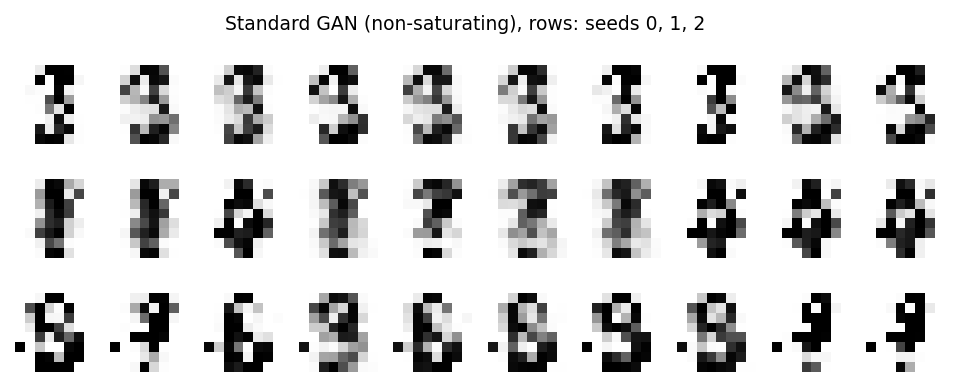

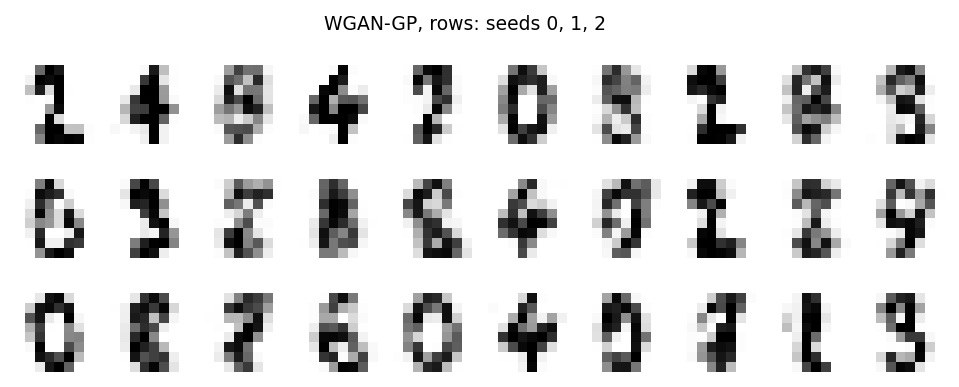

In [12]:
from IPython.display import Image, display
display(Image("figures/gan_standard_samples.png"))
display(Image("figures/gan_wgangp_samples.png"))

The pictures match the numbers. The standard GAN's seed 0 row is ten nearly identical 3s, and seeds 1 and 2 repeat a few shapes. Every WGAN-GP row has different digits across it, some of them smudged, but no repeats.